# Estimating annual visitors to African protected areas

**Mission.** My mission is to build practical, locally grounded tools that help African communities benefit from the places they protect.

**Use case.** Park managers and conservation planners use this model to get a baseline estimate of a protected area's annual visitors when no count exists, so they can plan staffing, budgets and fees. The target is annual visitors, a continuous number.

**Dataset.** The Database of African Protected Area Visitation (PAVIS v1.0): Buschke et al. (2025), *A dataset of pre-pandemic African protected area visitation*, Scientific Data 12, 764, https://doi.org/10.1038/s41597-025-04998-7. I use `clean_pavis.csv`, a cleaned copy (4,216 rows, 13 columns) from https://github.com/christianadebambo/africa-PA-forecasting (MIT licence). After my cleaning, 3,618 rows and 8 features remain (3 categorical, 5 numeric).

**How to run.** Run all cells from the top. `clean_pavis.csv` must be in the same folder as this notebook (in Colab, the data loading cell asks you to upload it).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

DATA_PATH = Path('clean_pavis.csv')
if not DATA_PATH.exists():
    from google.colab import files
    files.upload()

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Saving clean_pavis.csv to clean_pavis.csv
(4216, 13)


,wdpaid,pa_name,country,iucn_cat,governance,area_km2,year,visitors,lon,lat,iso3,status_year,rep_area_km2
0,9740.0,Chréa,Algeria,II,Federal or national ministry or agency,277.411685,2019,10000,2.853000,36.401000,DZA,1983.0,265.87
1,555698158.0,Belezma,Algeria,Not Applicable,Not Reported,661.277832,2019,50000,5.991000,35.587000,DZA,2015.0,656.70
2,9741.0,El Kala National Park,Algeria,II,Federal or national ministry or agency,778.454392,2019,30000,8.426000,36.806000,DZA,1983.0,796.47
3,347.0,Iona National Park,Angola,II,Not Reported,15174.440560,2016,4252,12.321550,-16.647913,AGO,1964.0,15150.00
4,348.0,Quiçama National Park,Angola,II,Not Reported,9229.345844,2020,2000,13.628347,-9.748898,AGO,1957.0,9960.00


Each row is one protected area's visitor count for one year. The columns are the park's identifiers (`wdpaid`, `pa_name`, `iso3`), its country, IUCN category and governance type, its area (`area_km2` and the reported `rep_area_km2`), the year, longitude and latitude, the year its current status started (`status_year`), and the target, `visitors`.

In [3]:
df.info()
print(df.isna().sum())
print((df['visitors'] == 0).sum(), "rows with zero visitors")
print(df['visitors'].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4216 entries, 0 to 4215
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   wdpaid        3982 non-null   float64
 1   pa_name       4216 non-null   object 
 2   country       4216 non-null   object 
 3   iucn_cat      4216 non-null   object 
 4   governance    4216 non-null   object 
 5   area_km2      3982 non-null   float64
 6   year          4216 non-null   int64  
 7   visitors      4216 non-null   int64  
 8   lon           4216 non-null   float64
 9   lat           4216 non-null   float64
 10  iso3          4216 non-null   object 
 11  status_year   3964 non-null   float64
 12  rep_area_km2  3982 non-null   float64
dtypes: float64(6), int64(2), object(5)
memory usage: 428.3+ KB
wdpaid          234
pa_name           0
country           0
iucn_cat          0
governance        0
area_km2        234
year              0
visitors          0
lon               0
lat 

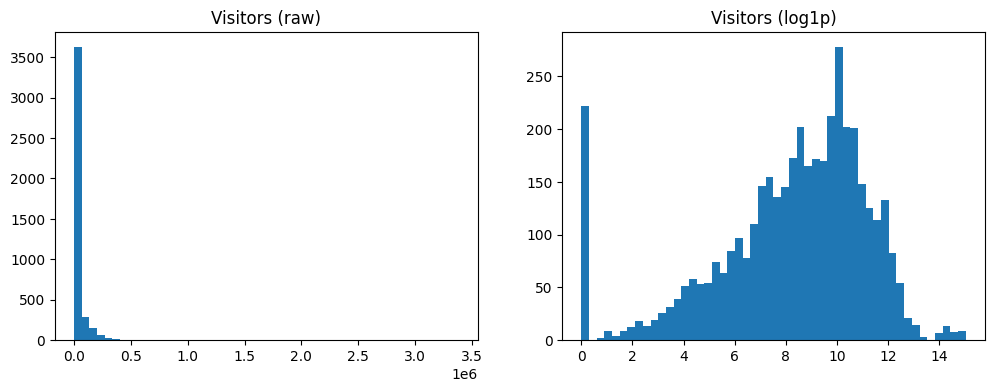

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['visitors'], bins=50)
axes[0].set_title('Visitors (raw)')
axes[1].hist(np.log1p(df['visitors']), bins=50)
axes[1].set_title('Visitors (log1p)')
plt.show()

**Target distribution.** The raw `visitors` histogram is extremely right-skewed: almost all protected areas fall in the first bin, while a few parks reach over 3 million visitors. After applying `log1p`, the distribution is much more balanced, with a peak near 10 (about 22,000 visitors) and a median of about 9 (roughly 7,900 visitors among parks with at least one visitor). It has a longer tail on the low side, plus a separate spike at 0 caused by 222 zero-visitor rows.
**Decision:** I will train the models on `log1p(visitors)` so that a few very large parks do not dominate the loss, and I will convert predictions back with `expm1` for the API. I will investigate the zero-visitor rows before deciding whether to keep them.

In [5]:
zeros = df[df['visitors'] == 0]
print(zeros['year'].value_counts().sort_index().tail(10))
print(zeros['country'].value_counts().head(5))
print(zeros['pa_name'].nunique(), "different parks")

print((df['area_km2'] > 1e6).sum(), "rows with absurd area_km2")
print((df['status_year'] == 0).sum(), "rows with status_year = 0")
print(df.duplicated(['pa_name', 'year']).sum(), "duplicate park-year rows")

year
2013     4
2014     6
2015     9
2016    29
2017     6
2018    16
2019    16
2020     8
2021     1
2022     2
Name: count, dtype: int64
country
Madagascar    120
Tanzania       18
Namibia        13
Rwanda          9
Ghana           9
Name: count, dtype: int64
79 different parks
22 rows with absurd area_km2
118 rows with status_year = 0
2 duplicate park-year rows


In [6]:
# Do the zero parks ever report a non-zero count?
park_max = df.groupby('pa_name')['visitors'].max()
zero_parks = zeros['pa_name'].unique()
print((park_max[zero_parks] == 0).sum(), "of", len(zero_parks), "zero parks never report any visitors")

# Are the rows with a missing area the same rows labelled 'unknown'?
print(df[df['rep_area_km2'].isna()]['iucn_cat'].value_counts())

# The 2 duplicate park-years: do their visitor counts differ?
print(df[df.duplicated(['pa_name', 'year'], keep=False)][['pa_name', 'year', 'visitors']])

23 of 79 zero parks never report any visitors
iucn_cat
unknown    234
Name: count, dtype: int64
                pa_name  year  visitors
178       Dzanga-Sangha  2016       542
182       Dzanga-Sangha  2016     12376
2810  Oiseaux du Djoudj  1998      5000
2820  Oiseaux du Djoudj  1998     10800


## Data cleaning and feature selection

**Rows removed (4,216 → 3,618).** I cleaned the data in code, without editing the CSV by hand, so every step is repeatable.

- **Zero-visitor rows (222 dropped).** A zero cannot be told apart from a missing count. Over half of these rows (120) come from Madagascar, and zeros are spread across all years rather than clustering in 2020–2021, so COVID closures do not explain them. Only 23 of the 79 affected parks never report any visitors, so this is a judgment call: I treated zeros as unreliable because they would drag predictions toward nonsense and create a false spike at 0 in the target.
- **Missing area (232 dropped).** These rows are also the rows labelled "unknown" for IUCN category and governance, so one drop removed all three problems at once.
- **Invalid `status_year` (109 dropped).** A value of 0 is not a real year, so I treated it as missing.
- **Conflicting duplicates (4 dropped).** Two park-year pairs (Dzanga-Sangha 2016 and Oiseaux du Djoudj 1998) appear twice with very different visitor counts (for example 542 vs 12,376), and I cannot tell which record is correct, so I removed both rows of each pair.
- **Impossible values found after the first cleaning pass (31 dropped).** Simien National Park has `status_year = 159` in 27 rows, and Mazie Kangari has a latitude of 57.0 in 4 rows, which is outside Africa. I could not tell what the correct values were, so I dropped these rows.
- **Encoding fix.** The country name "Côte d'Ivoire" contained a broken apostrophe character, which I replaced with a standard apostrophe so the API can accept the name.

**Columns not used as features.**
- `wdpaid` and `pa_name` are identifiers. A model cannot generalise from a park's name or ID to a new park, so keeping them would only let it memorise parks.
- `iso3` duplicates `country`, so keeping both adds no information.
- `area_km2` contains impossible values (22 rows above 1 million km², with a maximum of 2.11e14), so I used `rep_area_km2` instead, whose maximum is a realistic 52,800 km².
- `park_age` (engineered as `year - status_year`) was dropped because it is calculated from two features already in the data and is strongly correlated with `status_year` (-0.86), so it adds no new information.

**Kept as categories.** "Not Reported" and "Not Applicable" in `iucn_cat`, and "Not Reported" in `governance`, are large groups, so I kept them as their own categories rather than losing the rows.

**Features that matter most:** `country` by a wide margin, then `lon`, `lat`, `iucn_cat` and `status_year` (see the permutation importance chart below). `year` and `rep_area_km2` matter little, and `governance` adds essentially nothing.

In [7]:
df_clean = df.copy()
print("start:", len(df_clean))

# 1. zero visitors
df_clean = df_clean[df_clean['visitors'] > 0]
print("after dropping zero visitors:", len(df_clean))

# 2. missing area (these are also the 'unknown' category rows)
df_clean = df_clean.dropna(subset=['rep_area_km2'])
print("after dropping missing area:", len(df_clean))

# 3. invalid establishment years
df_clean['status_year'] = df_clean['status_year'].replace(0, np.nan)
df_clean = df_clean.dropna(subset=['status_year'])
print("after dropping bad status_year:", len(df_clean))

# 4. ambiguous park-year pairs
df_clean = df_clean[~df_clean.duplicated(['pa_name', 'year'], keep=False)]
print("after dropping ambiguous duplicates:", len(df_clean))

# 4b. impossible values found later: status_year before 1800, latitude outside Africa
df_clean = df_clean[df_clean['status_year'] >= 1800]
print("after dropping impossible status_year:", len(df_clean))
df_clean = df_clean[df_clean['lat'] <= 38]
print("after dropping impossible latitude:", len(df_clean))

# 4c. fix the broken apostrophe in Côte d'Ivoire
df_clean['country'] = df_clean['country'].str.replace('\x92', "'", regex=False)

# 5. engineered feature: park age
df_clean['park_age'] = df_clean['year'] - df_clean['status_year']
print((df_clean['park_age'] < 0).sum(), "rows with negative park_age")

df_clean = df_clean.reset_index(drop=True)

start: 4216
after dropping zero visitors: 3994
after dropping missing area: 3762
after dropping bad status_year: 3653
after dropping ambiguous duplicates: 3649
after dropping impossible status_year: 3622
after dropping impossible latitude: 3618
61 rows with negative park_age


In [8]:
neg = df_clean[df_clean['park_age'] < 0]
print(neg['park_age'].describe())
print(neg[['pa_name', 'year', 'status_year', 'park_age']].sort_values('park_age').head(8))

count    61.000000
mean     -5.770492
std       5.529899
min     -21.000000
25%      -8.000000
50%      -3.000000
75%      -2.000000
max      -1.000000
Name: park_age, dtype: float64
          pa_name  year  status_year  park_age
932  Lake Bogoria  1980       2001.0     -21.0
933  Lake Bogoria  1981       2001.0     -20.0
934  Lake Bogoria  1982       2001.0     -19.0
935  Lake Bogoria  1983       2001.0     -18.0
936  Lake Bogoria  1984       2001.0     -17.0
937  Lake Bogoria  1985       2001.0     -16.0
938  Lake Bogoria  1986       2001.0     -15.0
939  Lake Bogoria  1987       2001.0     -14.0


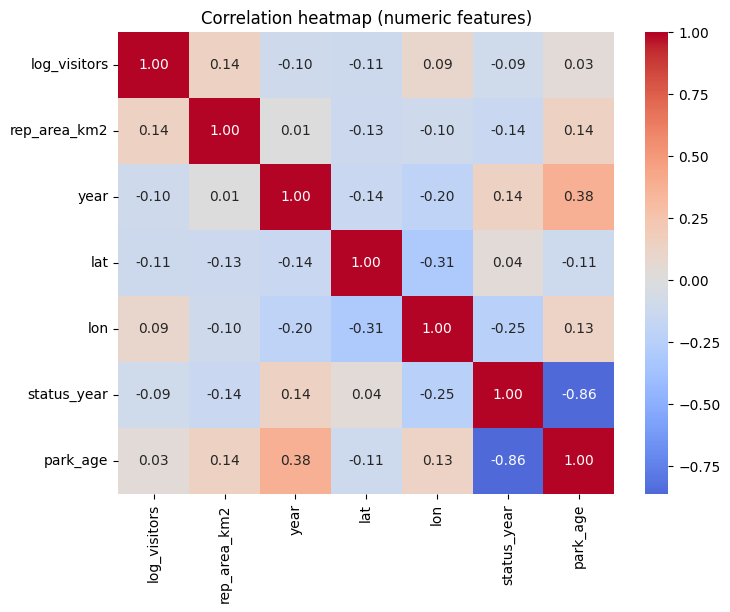

In [9]:
df_clean['log_visitors'] = np.log1p(df_clean['visitors'])

num_cols = ['log_visitors', 'rep_area_km2', 'year', 'lat', 'lon', 'status_year', 'park_age']
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric features)')
plt.show()

**Correlation heatmap.** The correlations between the numeric features and `log_visitors` are all weak. The strongest is `rep_area_km2` at 0.14, followed by `lat` (-0.11), `year` (-0.10), `lon` (0.09) and `status_year` (-0.09). A correlation of 0.14 means a straight line on park area alone would explain only about 2% of the variation in visitors, so I expect all models to find this problem hard, and I will check later whether the categorical features (`country`, `iucn_cat`, `governance`) help. `park_age` (`year - status_year`) is strongly correlated with `status_year` (-0.86) and is calculated from two features that are already in the data, so it adds no new information.
**Decision:** I dropped `park_age` and kept `status_year`, leaving 8 features. I will use `rep_area_km2`, the feature most correlated with the target, for the before and after scatter plots.

In [10]:
df_clean = df_clean.drop(columns=['park_age'])

features = ['country', 'iucn_cat', 'governance', 'rep_area_km2', 'year', 'lat', 'lon', 'status_year']
X = df_clean[features]
y = df_clean['log_visitors']
print(X.shape, y.shape)
print(X.dtypes)

(3618, 8) (3618,)
country          object
iucn_cat         object
governance       object
rep_area_km2    float64
year              int64
lat             float64
lon             float64
status_year     float64
dtype: object


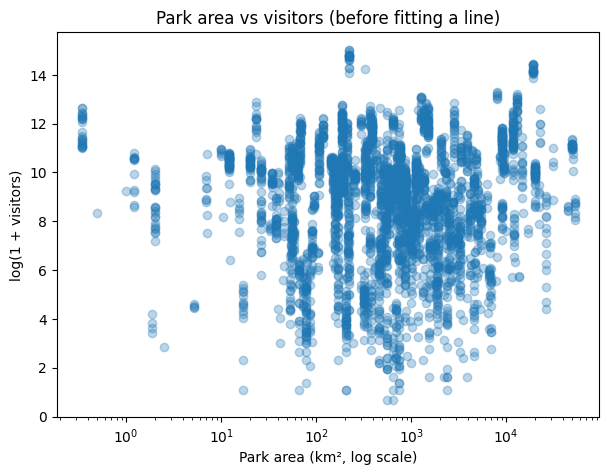

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df_clean['rep_area_km2'], df_clean['log_visitors'], alpha=0.3)
plt.xscale('log')
plt.xlabel('Park area (km², log scale)')
plt.ylabel('log(1 + visitors)')
plt.title('Park area vs visitors (before fitting a line)')
plt.show()

**Park area vs visitors.** The scatter plot shows a wide, noisy cloud with only a faint upward trend: parks of similar size can differ by several orders of magnitude in visitors, which fits the weak correlation of 0.14. The vertical stripes are single parks observed across many years (a park's area does not change), so rows from the same park are strongly related.
**Decision:** I will split the data by park, so no park appears in both the training and test sets. A random row split would put the same park in both, and the test score would look better than the model's real performance on a new park.

In [12]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df_clean['pa_name']))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)
overlap = set(df_clean.loc[train_idx, 'pa_name']) & set(df_clean.loc[test_idx, 'pa_name'])
print(len(overlap), "parks appear in both sets")

(2830, 8) (788, 8)
0 parks appear in both sets


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = ['country', 'iucn_cat', 'governance']
num_cols_model = ['rep_area_km2', 'year', 'lat', 'lon', 'status_year']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols_model),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print(X_train_p.shape, X_test_p.shape)

(2830, 54) (788, 54)


**Train/test split and preprocessing.** I split the data by park (2,830 training rows, 788 test rows) so that no park appears in both sets; the overlap check printed 0. This gives a more honest test score, because the model is tested on parks it has never seen. I one-hot encoded the three categorical columns (`country`, `iucn_cat`, `governance`) and standardized the five numeric columns, fitting the encoder and scaler on the training set only so no information from the test set leaks in. This produced 54 input columns.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print("Baseline (always predict the training mean), test MSE:", round(baseline_mse, 3))

models = {
    'Linear Regression (closed form)': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
}

results = {}
for name, m in models.items():
    m.fit(X_train_p, y_train)
    train_mse = mean_squared_error(y_train, m.predict(X_train_p))
    test_mse = mean_squared_error(y_test, m.predict(X_test_p))
    results[name] = (train_mse, test_mse)
    print(name, "- train MSE:", round(train_mse, 3), "| test MSE:", round(test_mse, 3))

Baseline (always predict the training mean), test MSE: 7.234
Linear Regression (closed form) - train MSE: 2.916 | test MSE: 4.38
Decision Tree - train MSE: 0.759 | test MSE: 5.689
Random Forest - train MSE: 0.137 | test MSE: 5.242


**Baseline and first three models.** All models are scored with mean squared error (MSE) on the same test set, on the log scale (so an MSE of 4 is not "4 visitors"). A baseline that always predicts the training mean scores 7.234, so any useful model must beat that. Closed form Linear Regression reaches a test MSE of 4.380 (train 2.916). The decision tree (train 0.759, test 5.689) and random forest (train 0.137, test 5.242) fit the training parks closely but do worse on the unseen test parks, a sign of overfitting.

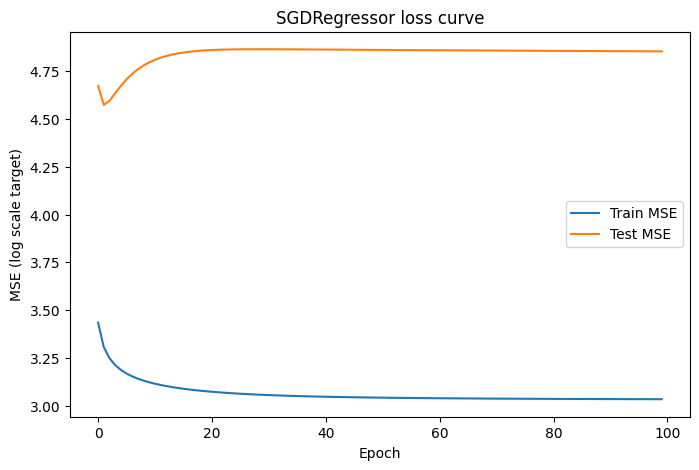

Final train MSE: 3.034 | final test MSE: 4.853


In [15]:
from sklearn.linear_model import SGDRegressor

def train_sgd(eta0, alpha, epochs=100):
    sgd = SGDRegressor(learning_rate='constant', eta0=eta0, penalty='l2', alpha=alpha, random_state=42)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        sgd.partial_fit(X_train_p, y_train)
        train_losses.append(mean_squared_error(y_train, sgd.predict(X_train_p)))
        test_losses.append(mean_squared_error(y_test, sgd.predict(X_test_p)))
    return sgd, train_losses, test_losses

sgd, train_losses, test_losses = train_sgd(eta0=0.01, alpha=0.0001, epochs=100)

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train MSE')
plt.plot(test_losses, label='Test MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE (log scale target)')
plt.title('SGDRegressor loss curve')
plt.legend()
plt.show()

print("Final train MSE:", round(train_losses[-1], 3), "| final test MSE:", round(test_losses[-1], 3))

**Untuned SGD loss curve (eta0 = 0.01, alpha = 0.0001).** Train MSE falls steadily to about 3.03, but test MSE reaches its lowest point (about 4.57) after the first epoch and then climbs to about 4.85, so the model starts to overfit. This is why I tuned the learning rate, the regularization strength and the number of epochs next.


In [16]:
rows = []
for eta0 in [0.001, 0.01, 0.1]:
    for alpha in [0.0001, 0.01, 1.0]:
        _, tr, te = train_sgd(eta0, alpha, epochs=100)
        rows.append({'eta0': eta0, 'alpha': alpha,
                     'train_mse': tr[-1], 'test_mse': te[-1],
                     'best_epoch': int(np.argmin(te)), 'best_test_mse': min(te)})
tuning = pd.DataFrame(rows).sort_values('test_mse')
print(tuning.round(3))

_, tr_long, te_long = train_sgd(0.01, 0.0001, epochs=300)
for e in [10, 50, 100, 300]:
    print("epochs =", e, "| train MSE:", round(tr_long[e-1], 3), "| test MSE:", round(te_long[e-1], 3))

    eta0  alpha     train_mse      test_mse  best_epoch  best_test_mse
1  0.001   0.01  3.171000e+00  4.058000e+00          99          4.058
0  0.001   0.00  3.007000e+00  4.312000e+00          24          4.156
4  0.010   0.01  3.282000e+00  4.529000e+00          99          4.529
3  0.010   0.00  3.034000e+00  4.853000e+00           1          4.573
2  0.001   1.00  4.878000e+00  6.227000e+00          30          6.227
5  0.010   1.00  4.978000e+00  6.792000e+00           3          6.792
8  0.100   1.00  6.368000e+00  9.422000e+00           0          9.422
7  0.100   0.01  3.179601e+18  3.798697e+18           0       1045.333
6  0.100   0.00  1.652775e+20  2.974451e+20           0     243812.751
epochs = 10 | train MSE: 3.122 | test MSE: 4.796
epochs = 50 | train MSE: 3.043 | test MSE: 4.861
epochs = 100 | train MSE: 3.034 | test MSE: 4.853
epochs = 300 | train MSE: 3.03 | test MSE: 4.836


**Tuning SGDRegressor.** I tried learning rates of 0.001, 0.01 and 0.1 and regularization strengths (alpha) of 0.0001, 0.01 and 1.0 over 100 epochs, and compared the final test MSE.
- **Learning rate:** 0.1 is too large, and the loss diverged to values around 1e18 and above because each step overshoots the minimum. 0.001 gave a lower test MSE than 0.01 at every alpha (for example 4.058 vs 4.529 at alpha 0.01).
- **Regularization (alpha):** 0.01 was best. At 0.0001 the model fits the training data slightly better but does worse on unseen parks (test MSE 4.312 vs 4.058), and at 1.0 the penalty is so strong that the model underfits (train MSE about 4.9 or higher).
- **Epochs:** with eta0 = 0.01 and alpha = 0.0001, test MSE was 4.796 after 10 epochs and 4.836 after 300, so running longer did not improve it, while train MSE kept falling slowly (3.12 to 3.03).

The best setting was eta0 = 0.001 and alpha = 0.01, with a test MSE of 4.058. I chose it using the test MSE, so this figure is slightly optimistic.

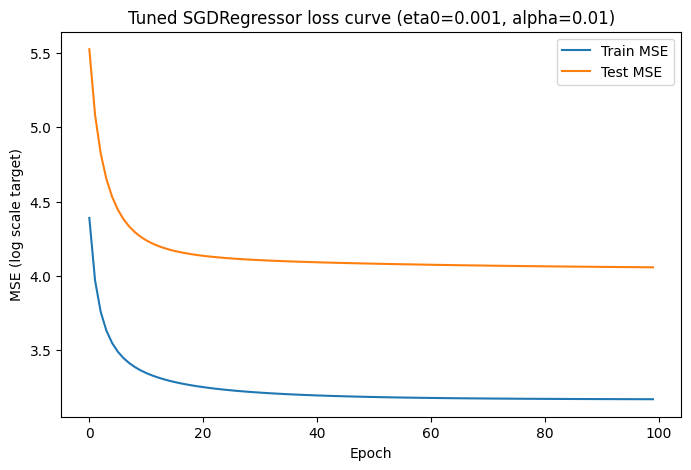

                          Model  Train MSE  Test MSE
           SGDRegressor (tuned)      3.171     4.058
Linear Regression (closed form)      2.916     4.380
                  Random Forest      0.137     5.242
                  Decision Tree      0.759     5.689
Baseline test MSE: 7.234


In [17]:
final_sgd, tr_f, te_f = train_sgd(eta0=0.001, alpha=0.01, epochs=100)

plt.figure(figsize=(8, 5))
plt.plot(tr_f, label='Train MSE')
plt.plot(te_f, label='Test MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE (log scale target)')
plt.title('Tuned SGDRegressor loss curve (eta0=0.001, alpha=0.01)')
plt.legend()
plt.show()

comparison = pd.DataFrame({
    'Model': ['SGDRegressor (tuned)', 'Linear Regression (closed form)', 'Decision Tree', 'Random Forest'],
    'Train MSE': [tr_f[-1],
                  results['Linear Regression (closed form)'][0],
                  results['Decision Tree'][0],
                  results['Random Forest'][0]],
    'Test MSE': [te_f[-1],
                 results['Linear Regression (closed form)'][1],
                 results['Decision Tree'][1],
                 results['Random Forest'][1]],
}).sort_values('Test MSE').round(3)
print(comparison.to_string(index=False))
print("Baseline test MSE:", round(baseline_mse, 3))

**Tuned SGDRegressor loss curve.** Train MSE falls smoothly to about 3.17, and test MSE falls from about 5.5 and levels off near 4.06 by epoch 100, with no sign of the test loss turning back up. The gap between the two curves shows the model does better on parks it has seen than on new ones. I used a fixed 100 epochs, since the curve has flattened by then.

## Model comparison

**Best model: SGDRegressor (eta0=0.001, alpha=0.01), with the lowest test MSE of 4.058.** It is about 7% lower than closed-form Linear Regression (4.380) and about 44% lower than always predicting the mean (7.234). I chose it purely on test MSE, as the brief requires. Because I also tuned its hyperparameters on the test set, 4.058 is a slightly optimistic estimate.

**How the dataset affected each model.**
- **Linear models (SGD and closed form):** the numeric features correlate only weakly with visitors, so most of what these models learn comes from the categorical columns, mainly `country`. Their train and test errors are fairly close (3.17 vs 4.06 for SGD), so they are not memorising.
- **Decision tree and random forest:** their train MSE is far below their test MSE (0.14 vs 5.24 for the forest). Latitude, longitude and area together identify a specific park, so the trees can memorise each park's usual visitor level. Because I split by park, the test parks are new, and that memory does not carry over, so the trees scored worse than the linear models.

I chose SGD because it generalises best to unseen parks, which matches the use case: estimating visitors for a park without counts.

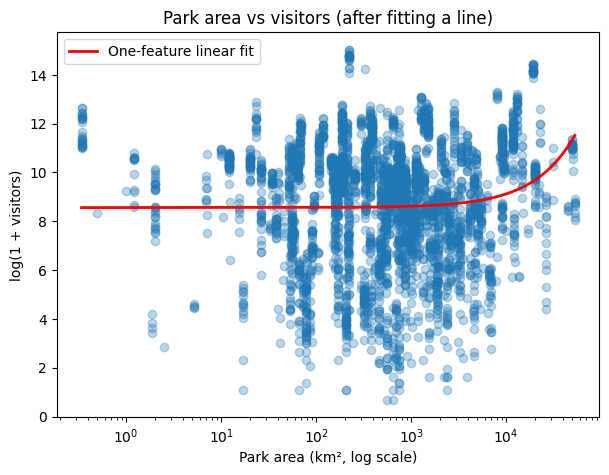

In [18]:
one_feat = LinearRegression()
one_feat.fit(df_clean[['rep_area_km2']], df_clean['log_visitors'])

xs = np.linspace(df_clean['rep_area_km2'].min(), df_clean['rep_area_km2'].max(), 200).reshape(-1, 1)
ys = one_feat.predict(pd.DataFrame(xs, columns=['rep_area_km2']))

plt.figure(figsize=(7, 5))
plt.scatter(df_clean['rep_area_km2'], df_clean['log_visitors'], alpha=0.3)
plt.plot(xs, ys, color='red', linewidth=2, label='One-feature linear fit')
plt.xscale('log')
plt.xlabel('Park area (km², log scale)')
plt.ylabel('log(1 + visitors)')
plt.title('Park area vs visitors (after fitting a line)')
plt.legend()
plt.show()

**Park area vs visitors, with fitted line.** A one-feature linear regression on `rep_area_km2` gives a line that is almost flat across most parks and rises only for the largest ones, which matches the weak correlation of 0.14. The line looks curved only because the x-axis is on a log scale. Park area alone is a poor predictor of visitors, so the model needs the other features.

In [19]:
import joblib, sklearn
from sklearn.pipeline import Pipeline

best_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', final_sgd),
])

joblib.dump(best_pipeline, 'best_model.pkl')
print("saved; scikit-learn version:", sklearn.__version__)

saved; scikit-learn version: 1.6.1


In [20]:
def predict_one(row_index=0, model_path='best_model.pkl'):
    model = joblib.load(model_path)
    row = X_test.iloc[[row_index]]
    log_pred = model.predict(row)[0]
    actual = np.expm1(y_test.iloc[row_index])
    return row.iloc[0].to_dict(), float(np.expm1(log_pred)), float(actual)

features_row, predicted, actual = predict_one(0)
print(features_row)
print("Predicted visitors:", round(predicted), "| actual visitors:", round(actual))

{'country': 'Algeria', 'iucn_cat': 'II', 'governance': 'Federal or national ministry or agency', 'rep_area_km2': 265.87, 'year': 2019, 'lat': 36.401, 'lon': 2.853, 'status_year': 1983.0}
Predicted visitors: 3123 | actual visitors: 10000


**Saving the best model and predicting one row.** I saved the best model (tuned SGDRegressor) together with its preprocessing as a single scikit-learn Pipeline in `best_model.pkl` using joblib, so raw inputs (country names, categories, areas) can be passed straight to it. `predict_one` loads the saved file, takes one row of the test set, and converts the model's log-scale output back to a visitor count with `expm1`. For test row 0 (Chréa, Algeria, 2019) it predicts about 3,123 visitors against an actual 10,000, which is consistent with the model's typical error of several times the true value.

country         3.436
lon             0.465
lat             0.306
iucn_cat        0.286
status_year     0.186
year            0.027
rep_area_km2    0.019
governance     -0.009
dtype: float64


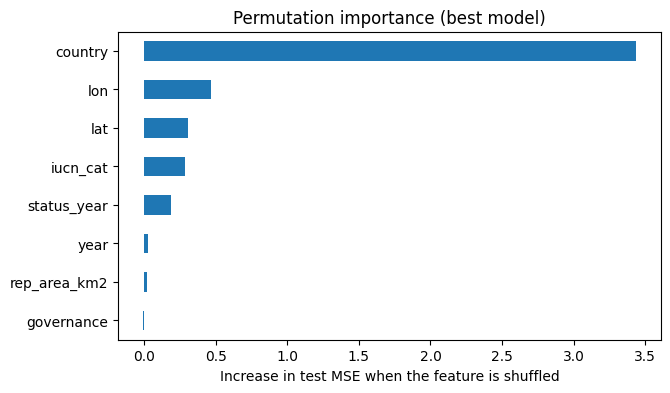

In [21]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_pipeline, X_test, y_test,
                              scoring='neg_mean_squared_error',
                              n_repeats=10, random_state=42)

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(importance.round(3))

importance.plot(kind='barh', figsize=(7, 4)).invert_yaxis()
plt.xlabel('Increase in test MSE when the feature is shuffled')
plt.title('Permutation importance (best model)')
plt.show()

**Permutation importance.** Shuffling each feature in the test set and measuring how much the test MSE rises shows that `country` matters far more than anything else (about +3.4), followed by `lon` (+0.46), `lat` (+0.30), `iucn_cat` (+0.28) and `status_year` (+0.18). `year` and `rep_area_km2` add very little, and `governance` is essentially zero. Longitude and latitude overlap with `country`, so their individual scores should be read with care. This explains why the numeric correlations in the heatmap were so weak: most of the usable signal sits in the categorical `country` column.